# Thực hành 1 — So sánh MLP và CNN

**Lê Sơn Trường — Buổi 4**. Theo `De_bai/baitap.txt` và các file mẫu.

Chọn **Select Kernel → DeepL (PyTorch)**. Môi trường có sẵn: `Buoi1/Buoi1_PyTorch/.venv/Scripts/python.exe`.

Notebook đã có output. **Run All huấn luyện lại thực sự** với 5 epoch mỗi cấu hình và cập nhật kết quả trong `results/`. Các hàm dùng trực tiếp từ `.py`; cell hiển thị mã lấy đúng nguồn hàm hiện tại, tránh hai bản code khác nhau.

## Quy trình chạy — Thực hành 1: so sánh MLP–CNN

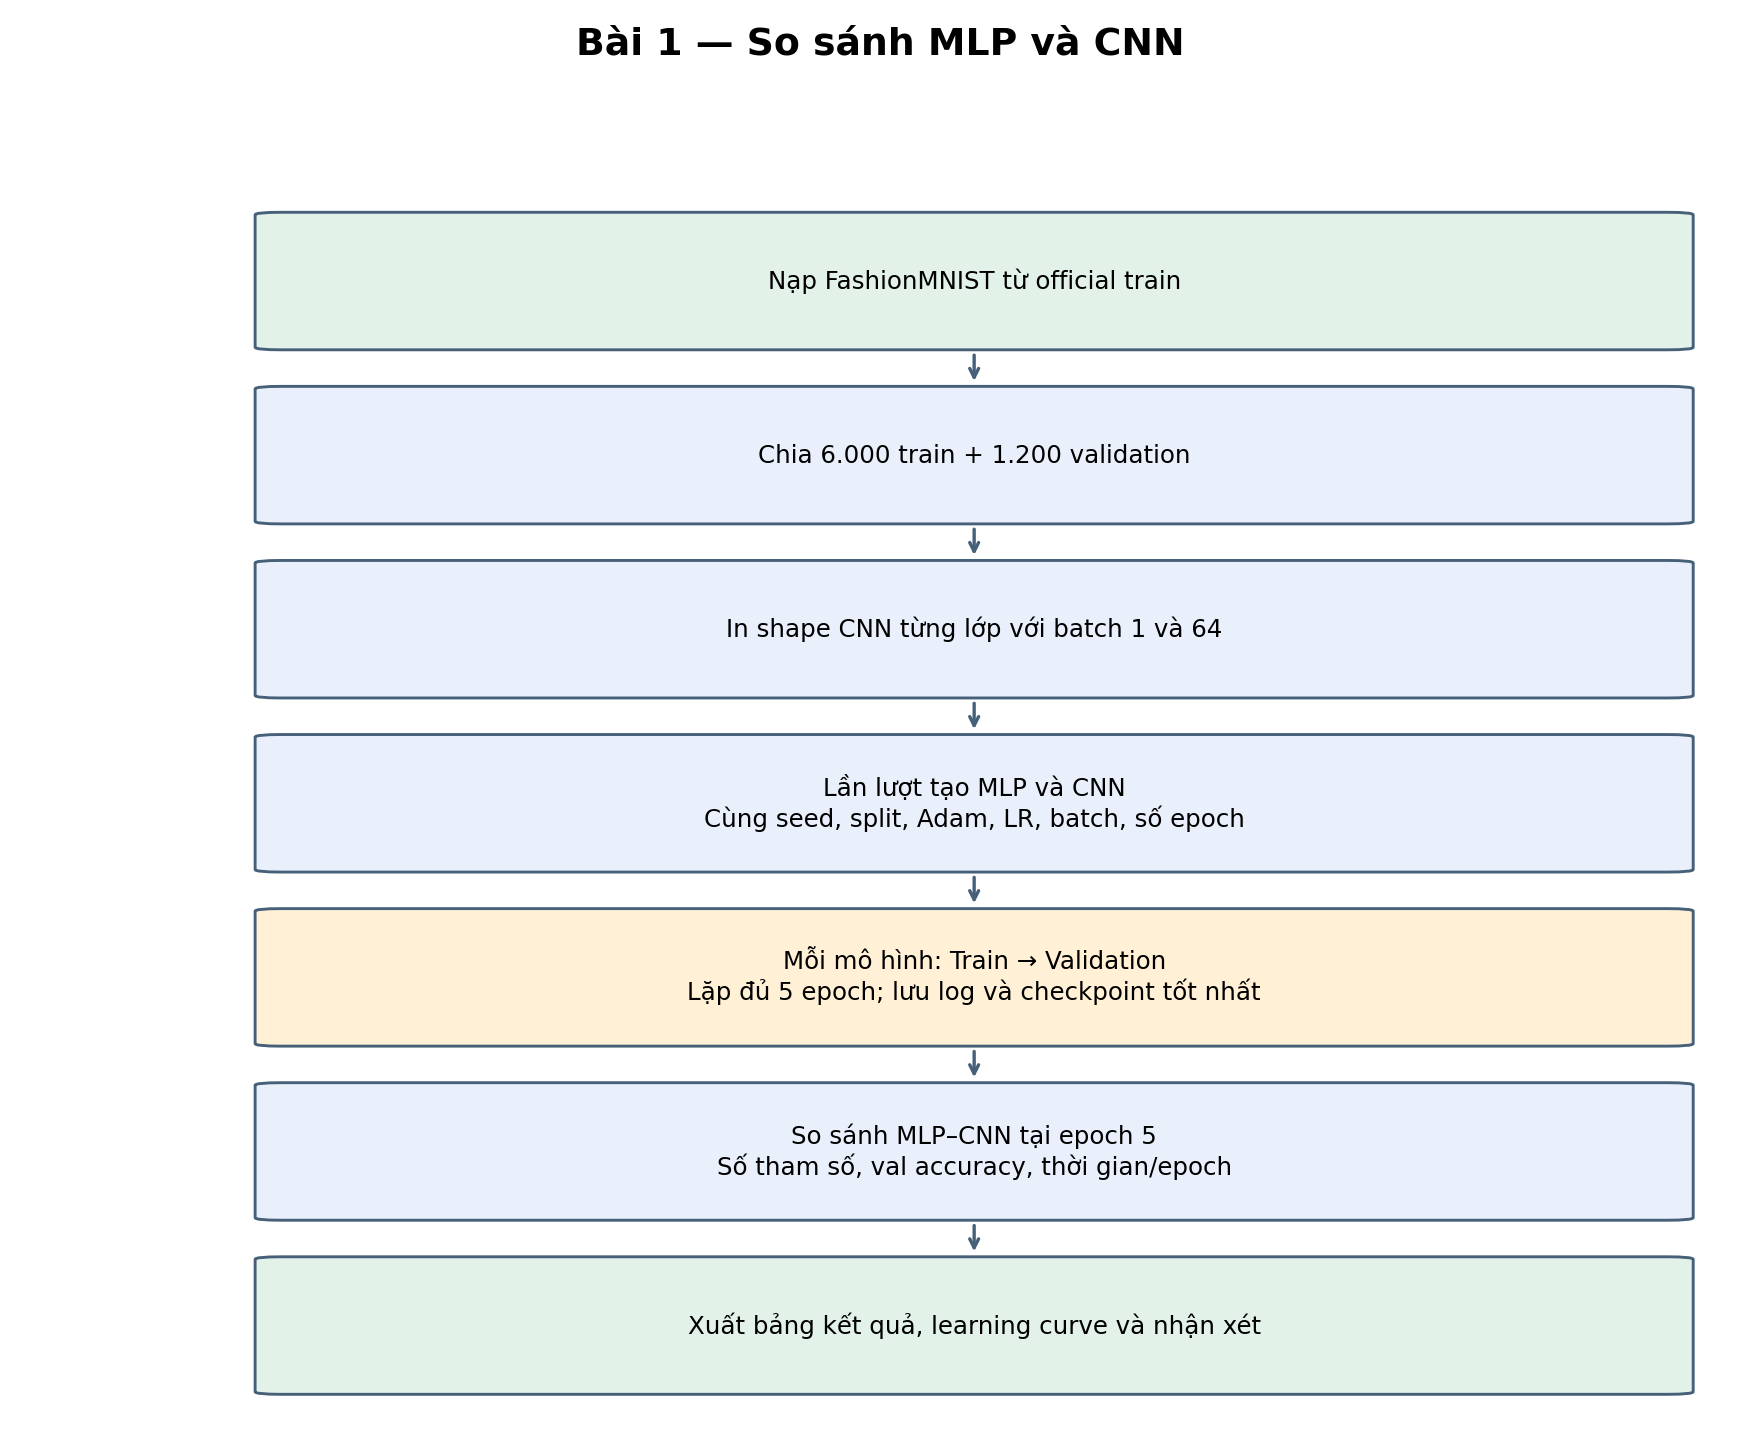

<details>
<summary>Mã Mermaid để chỉnh sửa sơ đồ</summary>

```mermaid
flowchart TD
    N0["Nạp FashionMNIST từ official train"]
    N1["Chia 6.000 train + 1.200 validation"]
    N0 --> N1
    N2["In shape CNN từng lớp với batch 1 và 64"]
    N1 --> N2
    N3["Lần lượt tạo MLP và CNN<br/>Cùng seed, split, Adam, LR, batch, số epoch"]
    N2 --> N3
    N4["Mỗi mô hình: Train → Validation<br/>Lặp đủ 5 epoch; lưu log và checkpoint tốt nhất"]
    N3 --> N4
    N5["So sánh MLP–CNN tại epoch 5<br/>Số tham số, val accuracy, thời gian/epoch"]
    N4 --> N5
    N6["Xuất bảng kết quả, learning curve và nhận xét"]
    N5 --> N6
```

</details>


**Luồng đọc nhanh:**

```text
Nạp official train → Chia 6000 train / 1200 validation
→ In shape → Lần lượt tạo MLP và CNN cùng optimizer
→ Với mỗi mô hình: 5 × [Train 1 epoch → Validation → Ghi log/checkpoint]
→ So sánh hai mô hình tại epoch 5
→ Lưu bảng kết quả, learning curve và nhận xét
```

| Bước | Công việc | Hàm thực hiện | Kết quả / ý nghĩa |
|---:|---|---|---|
| 1 | Khởi tạo | `main()` → `set_seed()` | Đặt seed42, xác định CPU/GPU; tạo thư mục `results/thuc_hanh_1/`. |
| 2 | Nạp và chia dữ liệu | `make_data()` → `read_official(train=True)` | Kiểm SHA-256; lấy 6.000 train và 1.200 validation từ hoán vị official train; pixel float32 /255, nhãn long. Lưu `split.json`. |
| 3 | Theo dõi tensor | `print_shapes()` | Chạy input giả với batch 1 và 64 qua conv1, pool1, conv2, pool2, Flatten và đầu ra; lưu `shapes.txt`. |
| 4 | Tạo từng mô hình | Vòng lặp MLP/CNN trong `main()` → `fit()` | Reset seed và thứ tự batch; tạo model trên device, Adam LR0.001, CrossEntropyLoss; đếm tham số. |
| 5 | Huấn luyện một epoch | `fit()` → `train_one_epoch()` | Bật train(); với mỗi batch64: zero_grad → forward → loss → backward → step. Cộng loss theo số mẫu. |
| 6 | Đánh giá và lặp | `fit()` → `evaluate()` | Bật eval(), dùng inference_mode trên 1.200 ảnh validation; ghi val loss/accuracy và giây/epoch; lưu checkpoint nếu validation tốt hơn. Lặp đủ 5 epoch rồi chuyển sang mô hình tiếp theo. |
| 7 | So sánh và xuất kết quả | Phần cuối `main()` | So sánh MLP–CNN tại epoch cuối bằng tham số, val accuracy và thời gian trung bình/epoch; xuất CSV, learning curve và báo cáo. |

Checkpoint tốt nhất vẫn được lưu để tham khảo. **Bảng so sánh chính của bài 1 dùng epoch 5**, đồng thời bảng chi tiết giữ đủ các epoch 1–5. Bài 1 chỉ dùng train/validation.

**File kết quả trong `results/thuc_hanh_1/`:** `split.json`, `shapes.txt`, `history.csv`, `summary.csv`, `metadata.json`, `MLP_best.pt`, `CNN_best.pt`, `learning_curves.png`, `report.md`.


In [1]:
from pathlib import Path
import importlib
import inspect
import re
import sys

cwd = Path.cwd().resolve()
candidates = [cwd, cwd / "Buoi4", *[p / "Buoi4" for p in cwd.parents]]
BASE = next((p for p in candidates if (p / "De_bai" / "baitap.txt").is_file()), None)
if BASE is None:
    raise FileNotFoundError("Mở notebook từ repository DeepL hoặc thư mục Buoi4.")
sys.path.insert(0, str(BASE))
try:
    import torch
except ModuleNotFoundError as error:
    if error.name != "torch":
        raise
    raise ModuleNotFoundError(
        "Chọn Select Kernel -> DeepL (PyTorch), rồi Restart Kernel và Run All. "
        f"Python hiện tại chưa có torch: {sys.executable}"
    ) from error

# Nạp đúng mã của Buổi 4, kể cả khi kernel đã dùng common.py của buổi khác.
importlib.invalidate_caches()
for name in ["reporting", "common", "bai03_class_cnn_fashionmnist", "bai03_homework_cnn_variants", "build_notebooks"]:
    sys.modules.pop(name, None)
import common
from IPython.display import Code, Image, Markdown, display
common.set_seed()
print("Người làm: Lê Sơn Trường")
print("Python:", sys.executable)
print("PyTorch:", torch.__version__, "| device:", common.DEVICE)
print("Train/validation: 6000/1200 từ official train; Adam; LR=0.001; batch64; 5 epoch.")

import bai03_class_cnn_fashionmnist as exercise

Người làm: Lê Sơn Trường
Python: C:\Users\LeSonTruong\Documents\GitHub\DeepL\Buoi1\Buoi1_PyTorch\.venv\Scripts\python.exe
PyTorch: 2.14.1+cpu | device: cpu
Train/validation: 6000/1200 từ official train; Adam; LR=0.001; batch64; 5 epoch.


## 1. Đầu vào, đầu ra và cách chia dữ liệu

Fashion-MNIST: ảnh xám `(N,1,28,28)`, nhãn long 0–9. Chuyển ảnh thành float32 /255, không augmentation. Train 6.000 và validation 1.200 ảnh không giao nhau, lấy từ cùng hoán vị official train với seed42. Đầu ra là 10 logits; `argmax` cho lớp dự đoán.

Bài này chỉ dùng train/validation; so sánh tại epoch cuối.

In [2]:
display(Code(inspect.getsource(common.make_data), language="python"))

def make_data(output):
    images, labels = read_official(train=True)
    ids = torch.randperm(len(labels), generator=torch.Generator().manual_seed(SEED))
    train_ids, val_ids = ids[:TRAIN_SIZE], ids[TRAIN_SIZE:TRAIN_SIZE + VAL_SIZE]
    assert not set(train_ids.tolist()) & set(val_ids.tolist())
    save_json(output / "split.json", {"seed": SEED, "source": "official train",
                                     "train_indices": train_ids.tolist(),
                                     "validation_indices": val_ids.tolist()})
    return tuple(TensorDataset(images[i].float().div_(255), labels[i])
                 for i in (train_ids, val_ids))

## 2. Kiến trúc và hình dạng tensor

MLP: 784 → 256 → 10. CNN: hai block Conv → ReLU → MaxPool, sau đó Flatten → Linear(1568,128) → ReLU → Linear(128,10). Hai mô hình cùng seed, split, Adam, LR, batch và số epoch.

### CNN hai block: dữ liệu đi qua mạng thế nào?

CNN **hai block** nghĩa là lặp hai lần cụm
**Conv2d → ReLU → MaxPool2d(2)**. Sau hai block mới đến phần phân loại.
Trong `common.py`, xem các chú thích `BLOCK 1`, `BLOCK 2`, `PHÂN LOẠI`
ở hàm `CNN2Blocks.forward()`.

Ví dụ dưới đây dùng **baseline**: kernel3, channels16/32, không BatchNorm/Dropout.
`N` là số ảnh trong batch (thường là 64), không phải số kênh.
Shape luôn có thứ tự **(số ảnh, số kênh, chiều cao, chiều rộng)**.

```text
Ảnh xám (N,1,28,28)
  │
  ├─ BLOCK 1
  │   Conv2d(1,16,3,padding=1) → (N,16,28,28)
  │   ReLU                    → (N,16,28,28)
  │   MaxPool2d(2)            → (N,16,14,14)
  │
  ├─ BLOCK 2
  │   Conv2d(16,32,3,padding=1)→ (N,32,14,14)
  │   ReLU                    → (N,32,14,14)
  │   MaxPool2d(2)            → (N,32,7,7)
  │
  └─ PHÂN LOẠI
      Flatten → (N,1568) → Linear → (N,128) → ReLU
      → Linear → (N,10) logits → argmax → nhãn dự đoán
```

**Bên trong từng phép tính:**

| Phép tính | Thực hiện thế nào? | Ý nghĩa |
|---|---|---|
| Conv2d | Trượt bộ lọc trên ảnh/đặc trưng. Tại mỗi vị trí, nhân từng giá trị với trọng số tương ứng, cộng lại trên cả vùng và các kênh đầu vào, rồi cộng bias. | Học đặc trưng cục bộ; dùng cùng trọng số ở các vị trí. |
| ReLU | Tính `max(0,x)`: số âm thành 0, số dương giữ nguyên. Không đổi shape. | Tạo tính phi tuyến, giúp mạng học quan hệ phức tạp. |
| MaxPool2d(2) | Mỗi kênh chia thành vùng 2×2, lấy giá trị lớn nhất; mặc định stride=2. | Giảm chiều cao/rộng còn một nửa, giữ số kênh. |

**Cụ thể với hai block:** Conv1 có 16 bộ lọc, mỗi bộ kích thước
`1×3×3`, tạo 16 bản đồ đặc trưng. Conv2 có 32 bộ lọc, mỗi bộ
`16×3×3`: mỗi giá trị đầu ra tổng hợp thông tin từ **cả 16 kênh**
của block 1, tạo 32 bản đồ đặc trưng mới. Các bộ lọc do mạng học
trong lúc huấn luyện, không phải bộ dò cạnh được đặt sẵn.

`padding=1` thêm viền 0 để convolution kernel3, stride1 giữ nguyên kích thước.
Công thức với dilation=1 là `H_out = floor((H + 2p - k)/s) + 1`;
ở conv1: `(28 + 2×1 - 3)/1 + 1 = 28`. Pooling mới giảm
`28→14` rồi `14→7`. Số ảnh trong batch luôn được giữ nguyên.

**Ví dụ nhỏ cho ReLU và MaxPool** (số minh họa, không phải kết quả huấn luyện):

```text
Một vùng đặc trưng    Sau ReLU        Sau MaxPool2d(2)
[-2,  3]             [0, 3]
[ 1, -4]       →     [1, 0]      →    3
```

**Sau hai block:** `32×7×7 = 1568` giá trị được trải phẳng cho mỗi ảnh.
`Linear(1568,128) → ReLU → Linear(128,10)` tạo 10 điểm số **logits**.
`argmax` chọn lớp có điểm cao nhất. Khi học, đưa logits trực tiếp vào
`CrossEntropyLoss`; không cần thêm Softmax trước loss.

**Các biến thể trong bài 2:**

- Kernel5 dùng padding2 nên vẫn giữ nguyên H,W sau convolution.
- Channels8 nghĩa là hai block có 8/16 kênh; channels32 nghĩa là 32/64 kênh.
  H,W vẫn đi theo `28→14→7`; số chiều sau Flatten thay đổi theo số kênh.
- BatchNorm: mỗi block thành `Conv2d → BatchNorm2d → ReLU → MaxPool2d(2)`.
  Ở baseline, `bn1/bn2` là `Identity`, cho dữ liệu đi qua nguyên vẹn.
- Dropout0.3 nằm **sau ReLU của Linear128**, ngoài hai block convolution.
  Nó ngẫu nhiên đặt một phần giá trị về 0 khi train; tắt khi eval.

**Liên hệ với quá trình học:** luồng trên là **forward**. Tiếp theo,
`loss → backward → optimizer.step()` tính lỗi, truyền gradient ngược
và cập nhật trọng số. Conv2d và Linear có tham số học được; ReLU,
MaxPool và Flatten không có trọng số học được. Với biến thể BatchNorm,
các tham số scale/bias của BatchNorm cũng được học.


In [3]:
display(Code(inspect.getsource(common.MLP), language="python"))
display(Code(inspect.getsource(common.CNN2Blocks), language="python"))
for batch_size in [1, 64]:
    exercise.print_shapes(common.CNN2Blocks(), batch_size)

class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 10))

    def forward(self, x):
        return self.net(x)

class CNN2Blocks(nn.Module):
    """Hai block trích đặc trưng rồi phân loại; N là số ảnh trong batch.

    Baseline: channels=16, kernel_size=3, không BatchNorm/Dropout.
    Mỗi block: Conv2d -> ReLU -> MaxPool2d(2).
    Biến thể BatchNorm chèn BN giữa Conv2d và ReLU.
    """

    def __init__(self, channels=16, kernel_size=3, batchnorm=False, dropout=0.0):
        super().__init__()
        self.conv1 = nn.Conv2d(1, channels, kernel_size, padding=kernel_size // 2)
        self.bn1 = nn.BatchNorm2d(channels) if batchnorm else nn.Identity()
        self.conv2 = nn.Conv2d(channels, 2 * channels, kernel_size, padding=kernel_size // 2)
        self.bn2 = nn.BatchNorm2d(2 * channels) if batchnorm else nn.Identity()
        self.relu, self.pool = nn.ReLU(), nn.MaxPool2d(2)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(2 * channels * 7 * 7, 128)
        self.drop = nn.Dropout(dropout)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        # BLOCK 1: (N,1,28,28) -> (N,C,14,14), baseline C=16.
        x = self.conv1(x)  # Học C bộ lọc: (N,C,28,28); padding giữ H,W.
        x = self.bn1(x)    # Identity ở baseline; BatchNorm ở biến thể BN.
        x = self.relu(x)   # max(0,x): bỏ giá trị âm, giữ nguyên shape.
        x = self.pool(x)   # Lấy max mỗi ô 2x2: 28x28 -> 14x14.

        # BLOCK 2: (N,C,14,14) -> (N,2C,7,7), baseline 2C=32.
        x = self.conv2(x)  # Mỗi bộ lọc kết hợp C kênh: (N,2C,14,14).
        x = self.bn2(x)
        x = self.relu(x)
        x = self.pool(x)   # 14x14 -> 7x7; không thay số kênh.

        # PHÂN LOẠI: (N,2C,7,7) -> (N,2C*7*7) -> (N,128) -> (N,10).
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.drop(x)   # p=0 ở baseline; p=0.3 ở biến thể Dropout.
        return self.fc2(x)  # 10 logits; CrossEntropyLoss nhận trực tiếp.

input: (1, 1, 28, 28)
conv1: (1, 16, 28, 28)
relu1: (1, 16, 28, 28)
pool1: (1, 16, 14, 14)
conv2: (1, 32, 14, 14)
relu2: (1, 32, 14, 14)
pool2: (1, 32, 7, 7)
before Linear: (1, 1568)
Linear + ReLU: (1, 128)
output: (1, 10)


input: (64, 1, 28, 28)
conv1: (64, 16, 28, 28)
relu1: (64, 16, 28, 28)
pool1: (64, 16, 14, 14)
conv2: (64, 32, 14, 14)
relu2: (64, 32, 14, 14)
pool2: (64, 32, 7, 7)
before Linear: (64, 1568)
Linear + ReLU: (64, 128)
output: (64, 10)


## Flow Train → Validation bên trong mỗi epoch

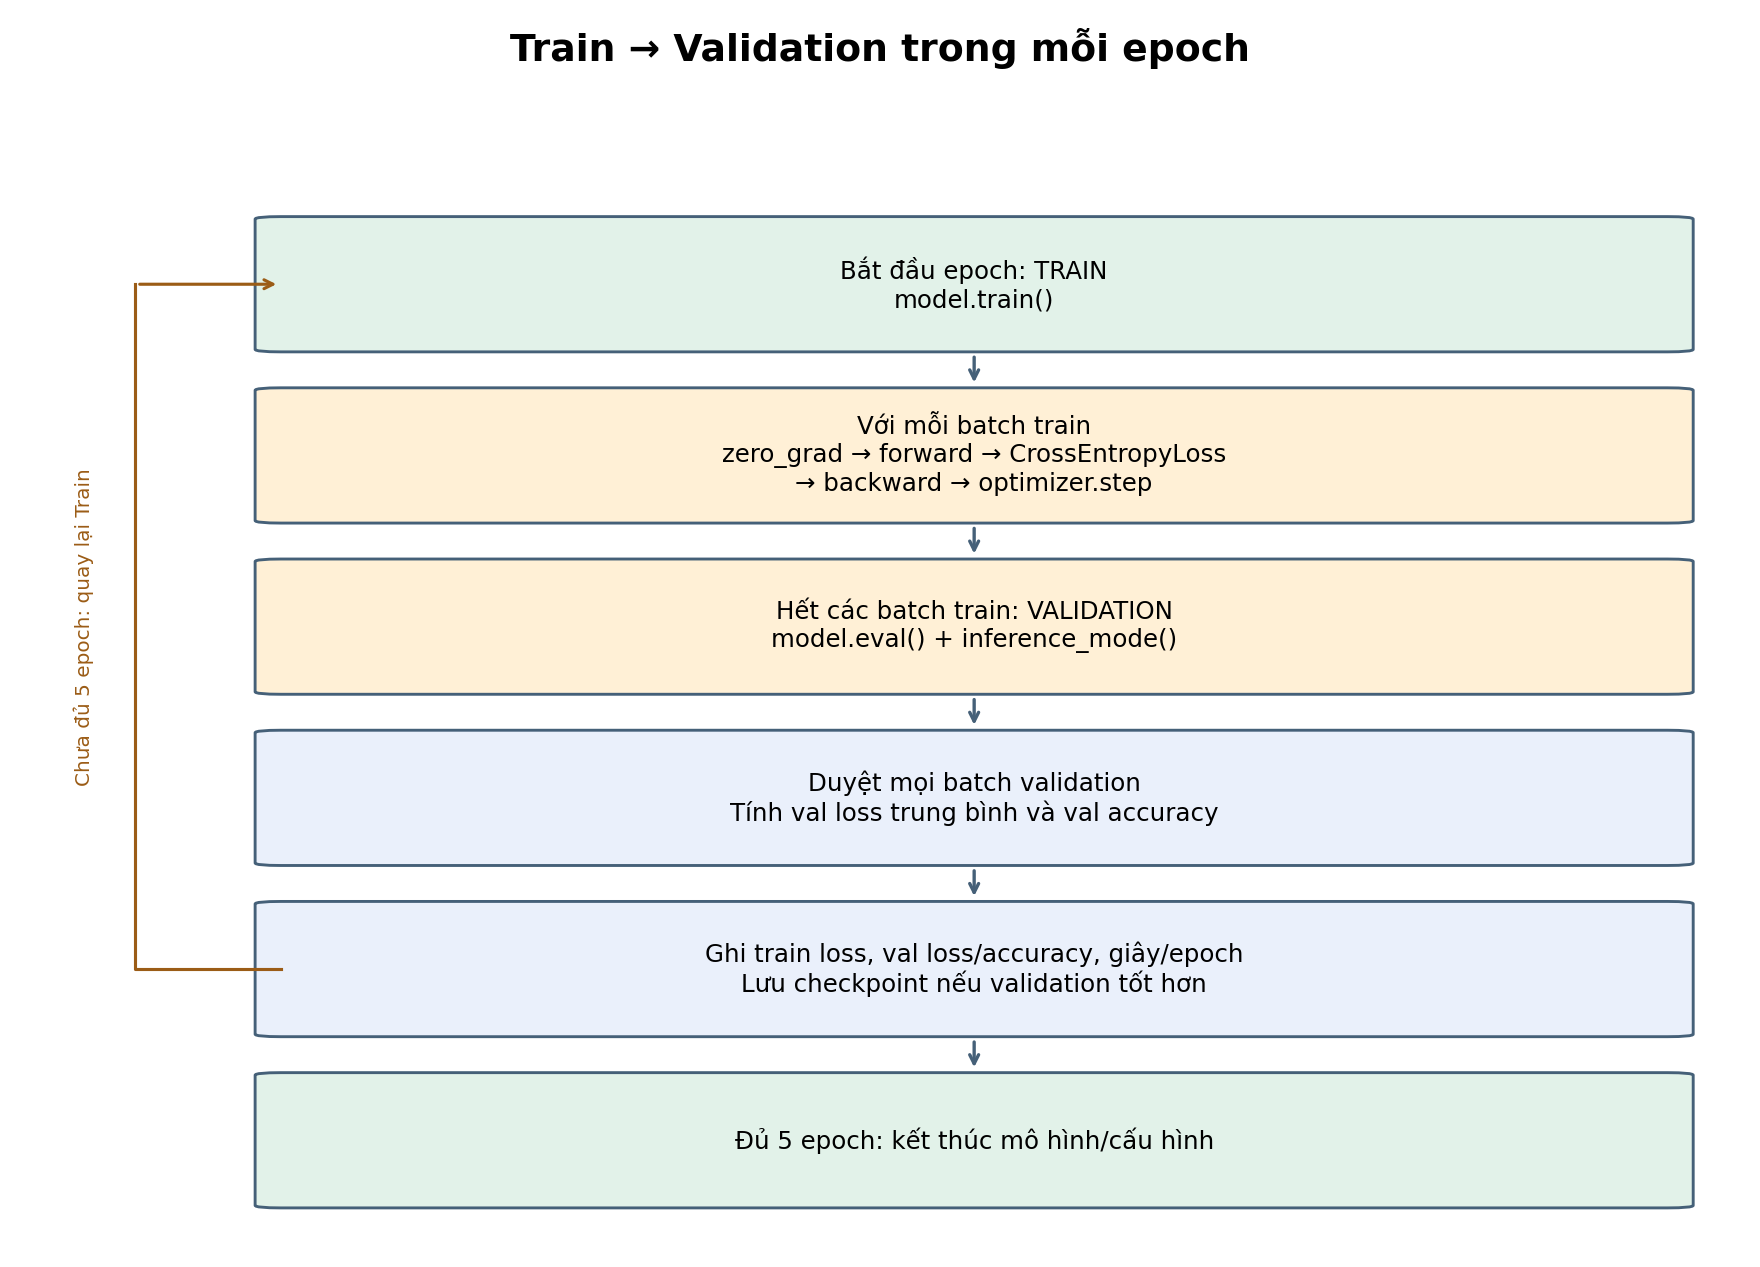

<details>
<summary>Mã Mermaid để chỉnh sửa sơ đồ</summary>

```mermaid
flowchart TD
    N0["Bắt đầu epoch: TRAIN<br/>model.train()"]
    N1["Với mỗi batch train<br/>zero_grad → forward → CrossEntropyLoss<br/>→ backward → optimizer.step"]
    N0 --> N1
    N2["Hết các batch train: VALIDATION<br/>model.eval() + inference_mode()"]
    N1 --> N2
    N3["Duyệt mọi batch validation<br/>Tính val loss trung bình và val accuracy"]
    N2 --> N3
    N4["Ghi train loss, val loss/accuracy, giây/epoch<br/>Lưu checkpoint nếu validation tốt hơn"]
    N3 --> N4
    N5["Đủ 5 epoch: kết thúc mô hình/cấu hình"]
    N4 --> N5
    N4 -->|"Chưa đủ 5 epoch"| N0
```

</details>

**Train cập nhật trọng số. Validation chỉ đo chất lượng và chọn checkpoint.** Bước cập nhật được thực hiện sau mỗi batch train; validation chạy ở cuối epoch. Cả hai bài đều dùng vòng học này. Test riêng của bài 2 diễn ra sau khi đã chọn mô hình.


## 3. Huấn luyện và đánh giá

Vòng học: zero_grad → forward → CrossEntropyLoss → backward → step. Dùng `train()` khi học, `eval()` và `inference_mode()` khi đánh giá. Loss lấy trung bình theo số mẫu, kể cả batch cuối thiếu. Train loss là loss trong khi cập nhật; validation loss đo ở cuối epoch. Thời gian gồm train + validation, không gồm ghi checkpoint hoặc vẽ hình.

In [4]:
display(Code(inspect.getsource(common.train_one_epoch), language="python"))
display(Code(inspect.getsource(common.evaluate), language="python"))
display(Code(inspect.getsource(common.fit), language="python"))

def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss, count = 0.0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * y.size(0)
        count += y.size(0)
    return total_loss / count

@torch.inference_mode()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, count = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        logits = model(x)
        total_loss += criterion(logits, y).item() * y.size(0)
        correct += (logits.argmax(1) == y).sum().item()
        count += y.size(0)
    return total_loss / count, correct / count

def fit(name, model, train_ds, val_ds, output):
    model = model.to(DEVICE)
    train_loader, val_loader = make_loaders(train_ds, val_ds)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    criterion = nn.CrossEntropyLoss()
    parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"\n{name} | device={DEVICE} | parameters={parameters}", flush=True)
    history, best_key, best_row = [], None, None
    for epoch in range(1, EPOCHS + 1):
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        start = time.perf_counter()
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion)
        val_loss, val_acc = evaluate(model, val_loader, criterion)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        elapsed = time.perf_counter() - start
        row = dict(model=name, epoch=epoch, train_loss=train_loss, val_loss=val_loss,
                   val_accuracy=val_acc, seconds=elapsed)
        history.append(row)
        print(f"Epoch {epoch}/{EPOCHS}: device={DEVICE}, train_loss={train_loss:.4f}, val_loss={val_loss:.4f}, "
              f"val_acc={val_acc:.2%}, time={elapsed:.2f}s", flush=True)
        key = (val_acc, -val_loss)
        if best_key is None or key > best_key:
            best_key, best_row = key, row.copy()
            torch.save({"state_dict": model.state_dict(), "epoch": epoch,
                        "val_accuracy": val_acc, "val_loss": val_loss}, output / f"{name}_best.pt")
    summary = dict(model=name, parameters=parameters, final_train_loss=history[-1]["train_loss"],
                   final_val_loss=history[-1]["val_loss"], final_val_accuracy=history[-1]["val_accuracy"],
                   mean_seconds_per_epoch=float(np.mean([r["seconds"] for r in history])),
                   best_epoch=best_row["epoch"], best_val_loss=best_row["val_loss"],
                   best_val_accuracy=best_row["val_accuracy"])
    return summary, history

## Chạy thí nghiệm

Cell này gọi trực tiếp `main()` của script cùng tên; học đủ 5 epoch mỗi cấu hình. Các file dữ liệu và checkpoint được tạo theo đúng quy trình trong mã nguồn.

In [5]:
exercise.main()

Device: cpu | train: 6000 | validation: 1200


input: (1, 1, 28, 28)
conv1: (1, 16, 28, 28)
relu1: (1, 16, 28, 28)
pool1: (1, 16, 14, 14)
conv2: (1, 32, 14, 14)
relu2: (1, 32, 14, 14)
pool2: (1, 32, 7, 7)
before Linear: (1, 1568)
Linear + ReLU: (1, 128)
output: (1, 10)


input: (64, 1, 28, 28)
conv1: (64, 16, 28, 28)
relu1: (64, 16, 28, 28)
pool1: (64, 16, 14, 14)
conv2: (64, 32, 14, 14)
relu2: (64, 32, 14, 14)
pool2: (64, 32, 7, 7)
before Linear: (64, 1568)
Linear + ReLU: (64, 128)
output: (64, 10)



MLP | device=cpu | parameters=203530


Epoch 1/5: device=cpu, train_loss=0.9494, val_loss=0.5953, val_acc=80.08%, time=0.11s


...

Epoch 2/5: device=cpu, train_loss=0.6478, val_loss=0.5777, val_acc=78.75%, time=0.67s


Epoch 3/5: device=cpu, train_loss=0.5521, val_loss=0.4893, val_acc=81.75%, time=0.68s


Epoch 4/5: device=cpu, train_loss=0.4973, val_loss=0.4830, val_acc=82.50%, time=0.73s


Epoch 5/5: device=cpu, train_loss=0.4617, val_loss=0.4319, val_acc=86.17%, time=0.70s



| Mô hình | Tham số | Val loss | Val accuracy | Giây/epoch | Epoch báo cáo |
|---|---:|---:|---:|---:|---:|
| MLP | 203,530 | 0.4766 | 82.83% | 0.100 | 5 |
| CNN | 206,922 | 0.4319 | 86.17% | 0.687 | 5 |


## Bảng kết quả từng epoch, learning curve và nhận xét

Bảng chi tiết hiển thị đủ epoch 1–5 cho từng mô hình: train loss, val loss, val accuracy, thay đổi accuracy và thời gian. Epoch in đậm là checkpoint validation tốt nhất; xem ghi chú để phân biệt với epoch cuối và mô hình chính được chọn.

# Thực hành 1 — Lê Sơn Trường

| Mô hình | Tham số | Val loss | Val accuracy | Giây/epoch | Epoch báo cáo |
|---|---:|---:|---:|---:|---:|
| MLP | 203,530 | 0.4766 | 82.83% | 0.100 | 5 |
| CNN | 206,922 | 0.4319 | 86.17% | 0.687 | 5 |

Bảng dùng epoch cuối (5); cùng seed42, split6000/1200, Adam, lr0.001, batch64.

<!-- BEGIN EPOCH_DETAILS -->

### Kết quả đầy đủ từng epoch

**Train loss**: trung bình theo số mẫu trong lúc cập nhật. **Val loss/accuracy**: đánh giá ở cuối epoch. **Δ accuracy**: thay đổi so với epoch trước, tính bằng điểm phần trăm. **Giây**: thời gian train + validation của epoch đó.

Epoch **in đậm** có validation accuracy cao nhất của cấu hình; nếu hòa, chọn validation loss nhỏ hơn. Bảng tổng kết bài 1 vẫn dùng epoch cuối để so sánh cùng ngân sách.

[Dữ liệu từng epoch: history.csv](history.csv)

#### MLP

| Epoch | Train loss | Val loss | Val accuracy | Δ accuracy (điểm %) | Giây | Ghi chú |
|---:|---:|---:|---:|---:|---:|---|
| 1 | 0.9494 | 0.5953 | 80.08% | — | 0.109 | — |
| 2 | 0.5999 | 0.5241 | 82.25% | +2.17 | 0.097 | — |
| **3** | 0.5264 | 0.4831 | 83.33% | +1.08 | 0.097 | Val tốt nhất |
| 4 | 0.4840 | 0.4918 | 81.92% | -1.42 | 0.097 | — |
| 5 | 0.4501 | 0.4766 | 82.83% | +0.92 | 0.098 | Epoch cuối |

Từ epoch 1 → 5: train loss 0.9494 → 0.4501; val loss 0.5953 → 0.4766; val accuracy 80.08% → 82.83%. Accuracy cao nhất là **83.33% tại epoch 3**.

Val loss thấp nhất lại ở **epoch 5** (0.4766). Loss và accuracy đo hai khía cạnh khác nhau, nên epoch có loss thấp nhất không nhất thiết có accuracy cao nhất.

#### CNN

| Epoch | Train loss | Val loss | Val accuracy | Δ accuracy (điểm %) | Giây | Ghi chú |
|---:|---:|---:|---:|---:|---:|---|
| 1 | 1.1296 | 0.6584 | 76.92% | — | 0.650 | — |
| 2 | 0.6478 | 0.5777 | 78.75% | +1.83 | 0.673 | — |
| 3 | 0.5521 | 0.4893 | 81.75% | +3.00 | 0.680 | — |
| 4 | 0.4973 | 0.4830 | 82.50% | +0.75 | 0.733 | — |
| **5** | 0.4617 | 0.4319 | 86.17% | +3.67 | 0.699 | Val tốt nhất; Epoch cuối |

Từ epoch 1 → 5: train loss 1.1296 → 0.4617; val loss 0.6584 → 0.4319; val accuracy 76.92% → 86.17%. Accuracy cao nhất là **86.17% tại epoch 5**.

<!-- END EPOCH_DETAILS -->



```text
input: (1, 1, 28, 28)
conv1: (1, 16, 28, 28)
relu1: (1, 16, 28, 28)
pool1: (1, 16, 14, 14)
conv2: (1, 32, 14, 14)
relu2: (1, 32, 14, 14)
pool2: (1, 32, 7, 7)
before Linear: (1, 1568)
Linear + ReLU: (1, 128)
output: (1, 10)

input: (64, 1, 28, 28)
conv1: (64, 16, 28, 28)
relu1: (64, 16, 28, 28)
pool1: (64, 16, 14, 14)
conv2: (64, 32, 14, 14)
relu2: (64, 32, 14, 14)
pool2: (64, 32, 7, 7)
before Linear: (64, 1568)
Linear + ReLU: (64, 128)
output: (64, 10)
```

Tensor CNN đi từ (N,1,28,28) qua (N,16,28,28), (N,16,14,14), (N,32,14,14), (N,32,7,7), rồi flatten thành (N,1568); chiều N là batch và được giữ nguyên.

MLP có 203,530 tham số và CNN có 206,922 tham số; convolution dùng chung trọng số theo vị trí, nhưng lớp Linear 1568→128 vẫn chiếm phần lớn tham số CNN.

Sau 5 epoch, MLP đạt 82.83% và CNN đạt 86.17% validation accuracy, tức CNN cao hơn 3.33 điểm phần trăm.

Thời gian trung bình gồm train và validation là 0.100 s/epoch cho MLP và 0.687 s/epoch cho CNN trên cpu; số tham số gần nhau không có nghĩa số phép tính giống nhau.

Kết quả chỉ phản ánh một seed và 5 epoch trên split này; train loss đo trong lúc cập nhật, còn validation loss đo cuối epoch nên hai đường loss không hoàn toàn cùng thời điểm.


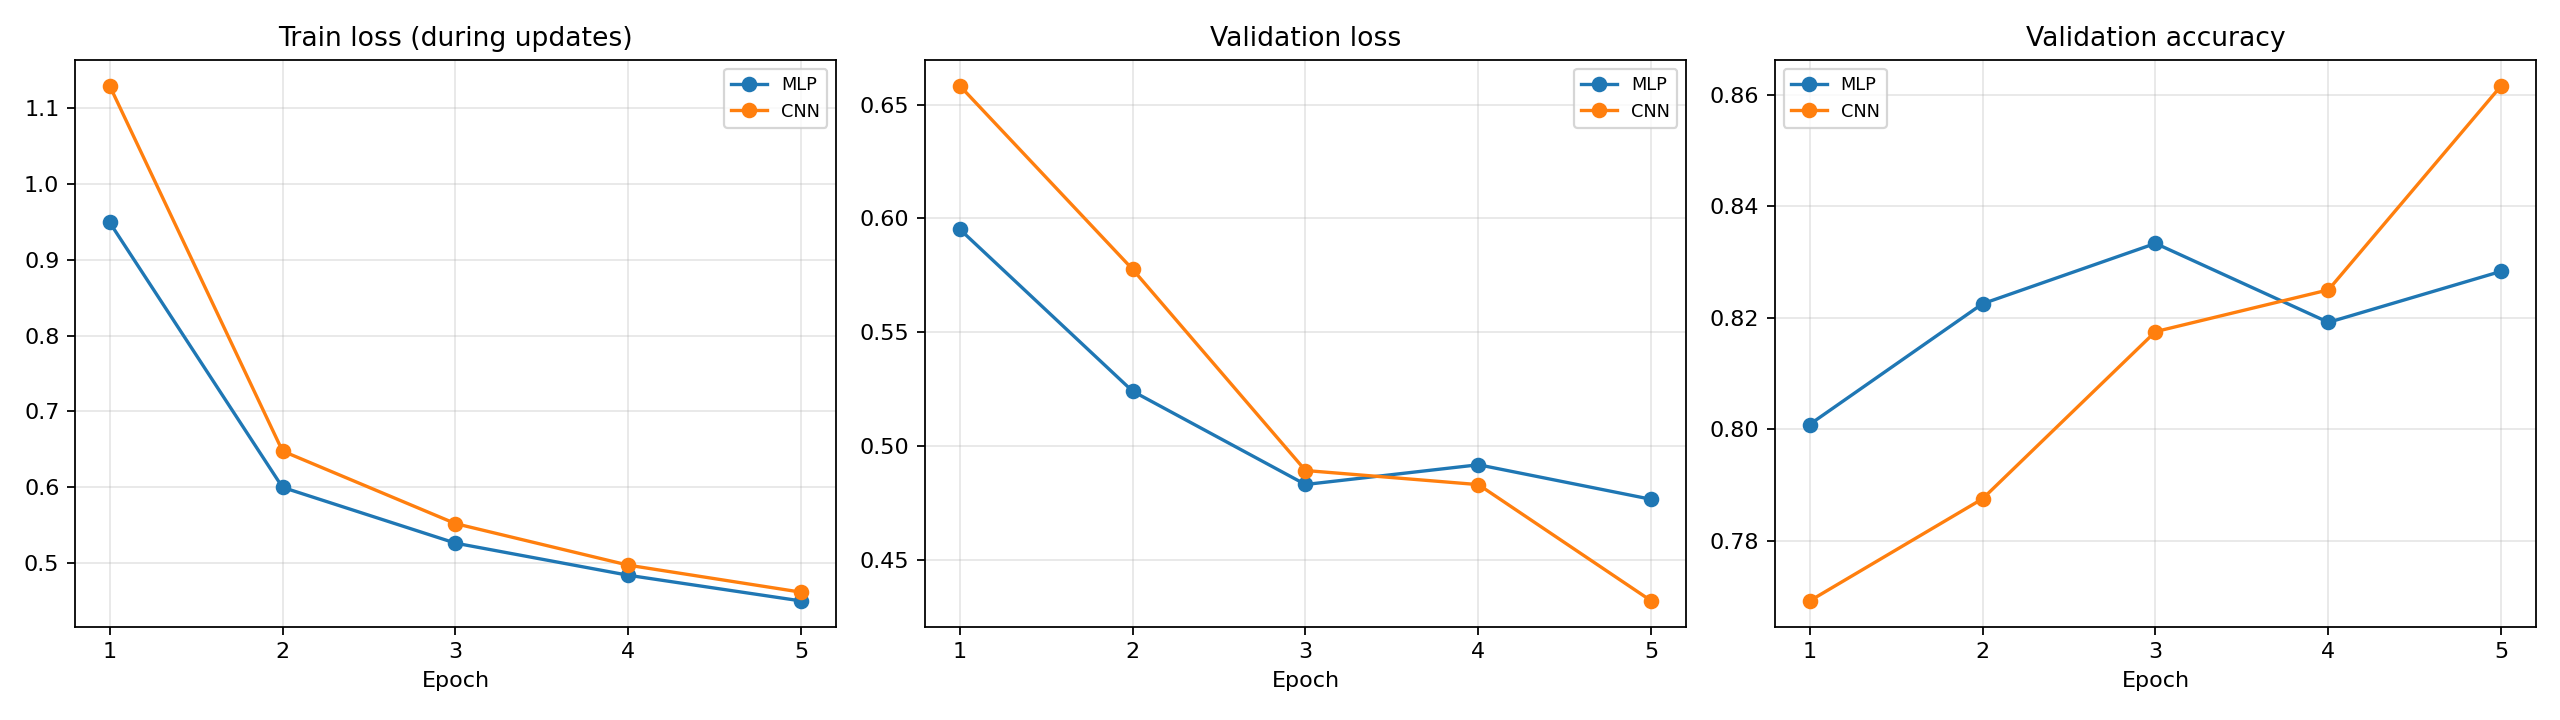

In [5]:
folder = BASE / "results" / "thuc_hanh_1"
report = (folder / "report.md").read_text(encoding="utf-8")
display(Markdown(re.sub(r"!\[[^\]]*\]\([^)]+\)", "", report)))
for filename in ['learning_curves.png']:
    display(Image(filename=str(folder / filename)))

## Báo cáo tổng hợp

`BAO_CAO_BUOI4.md` tổng hợp hai bài, kèm hình và phân tích ma trận nhầm lẫn. Khi thay đổi cấu hình, chạy lại cả hai notebook rồi kiểm tra kết quả.

In [6]:
from build_notebooks import write_combined_report
if all((BASE / "results" / task / "report.md").is_file() for task in ["thuc_hanh_1", "thuc_hanh_2"]):
    print("Đã cập nhật:", write_combined_report())
else:
    print("Chạy đủ hai bài để tạo báo cáo tổng hợp.")

Đã cập nhật: C:\Users\LeSonTruong\Documents\GitHub\DeepL\Buoi4\BAO_CAO_BUOI4.md
